In [1]:
import numpy as np
import matplotlib.pyplot as plt
# ---------------------------
# Activation Functions
# ---------------------------
def sigmoid(x):
  return 1 / (1 + np.exp(-x))
def sigmoid_derivative(x):
  # Note: x here is expected to be the output of the sigmoid function
  return x * (1 - x)

In [2]:
def train_neural_network(learning_rate, epochs=10000):
  input_neurons = 2
  hidden_neurons = 2
  output_neurons = 1
# Resetting the seed ensures every learning rate starts with the SAME weights
  np.random.seed(1)
# Weight initialization
  W1 = np.random.rand(input_neurons, hidden_neurons)
  W2 = np.random.rand(hidden_neurons, output_neurons)
# Bias initialization
  b1 = np.random.rand(1, hidden_neurons)
  b2 = np.random.rand(1, output_neurons)
  loss_history = []
# ---------------------------
# Training Loop
# ---------------------------
  for epoch in range(epochs):
# Forward propagation
    hidden_input = np.dot(X, W1) + b1
    hidden_output = sigmoid(hidden_input)
    final_input = np.dot(hidden_output, W2) + b2
    predicted_output = sigmoid(final_input)
# Loss calculation (Mean Squared Error)
    loss = np.mean((y - predicted_output)**2)
    loss_history.append(loss)
# Backpropagation
    error = y - predicted_output
    d_output = error * sigmoid_derivative(predicted_output)
    error_hidden = d_output.dot(W2.T)
    d_hidden = error_hidden * sigmoid_derivative(hidden_output)
# Weight & Bias updates
    W2 += hidden_output.T.dot(d_output) * learning_rate
    W1 += X.T.dot(d_hidden) * learning_rate
    b2 += np.sum(d_output, axis=0, keepdims=True) * learning_rate
    b1 += np.sum(d_hidden, axis=0, keepdims=True) * learning_rate
# Final forward pass to get the clean output after all training
  final_hidden = sigmoid(np.dot(X, W1) + b1)
  final_out = sigmoid(np.dot(final_hidden, W2) + b2)
  return final_out, loss_history

Actual Output:
[[0]
 [1]
 [1]
 [0]] 

------------------------------
Predicted Output (Learning Rate = 0.1):
[[0.073 ]
 [0.9309]
 [0.9312]
 [0.0756]]
------------------------------
Predicted Output (Learning Rate = 0.4):
[[0.0224]
 [0.9805]
 [0.9806]
 [0.0202]]
------------------------------
Predicted Output (Learning Rate = 0.7):
[[0.0161]
 [0.9862]
 [0.9862]
 [0.0142]]
------------------------------
Predicted Output (Learning Rate = 0.9):
[[0.0139]
 [0.9881]
 [0.9881]
 [0.0123]]
------------------------------


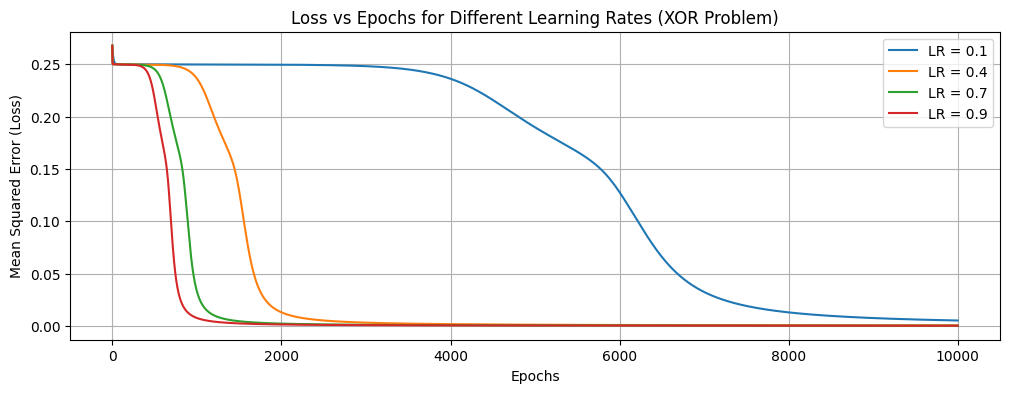

In [5]:
# ---------------------------
# Dataset (XOR Problem)
# ---------------------------
X = np.array([[0, 0],
  [0, 1],
  [1, 0],
  [1, 1]])
y = np.array([[0],
[1],
[1],
[0]])
learning_rates = [0.1, 0.4, 0.7, 0.9]
epochs = 10000
plt.figure(figsize=(12, 4))
print("Actual Output:")
print(y,"\n")
print("-" * 30)
for lr in learning_rates:
# Train the network
  final_output, loss_history = train_neural_network(learning_rate=lr,epochs=epochs)
# Print results
  print(f"Predicted Output (Learning Rate = {lr}):")
  print(np.round(final_output, 4)) # Rounded for cleaner reading
  print("-" * 30)


# Add to plot
  plt.plot(loss_history, label=f'LR = {lr}')
# ---------------------------
# Plot Formatting
# ---------------------------
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (Loss)")
plt.title("Loss vs Epochs for Different Learning Rates (XOR Problem)")
plt.legend()
plt.grid(True)
plt.show()

Actual Output (XNOR):
[[1]
 [0]
 [0]
 [1]] 

------------------------------
Predicted Output (Learning Rate = 0.1):
[[0.9387]
 [0.0568]
 [0.0566]
 [0.9387]]
------------------------------
Predicted Output (Learning Rate = 0.4):
[[0.9781]
 [0.019 ]
 [0.019 ]
 [0.9803]]
------------------------------
Predicted Output (Learning Rate = 0.7):
[[0.9841]
 [0.0136]
 [0.0136]
 [0.9859]]
------------------------------
Predicted Output (Learning Rate = 0.9):
[[0.9862]
 [0.0118]
 [0.0118]
 [0.9878]]
------------------------------


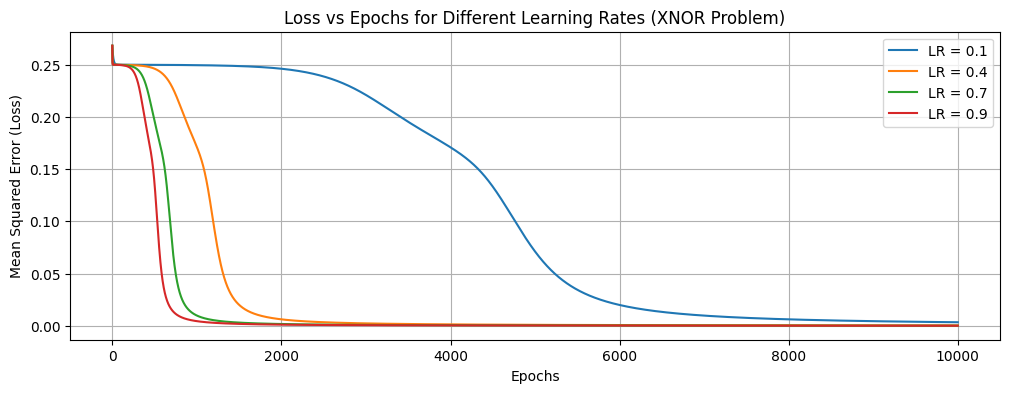

In [6]:
# ---------------------------
# Dataset (XNOR Problem)
# ---------------------------
# XNOR outputs 1 when inputs are equal, 0 otherwise
X = np.array([[0, 0],
[0, 1],
[1, 0],
[1, 1]])
y = np.array([[1],
[0],
[0],
[1]])
# ---------------------------
# Execution & Plotting
# ---------------------------
learning_rates = [0.1, 0.4, 0.7, 0.9]
epochs = 10000
plt.figure(figsize=(12, 4))
print("Actual Output (XNOR):")
print(y,"\n")
print("-" * 30)
for lr in learning_rates:
# Train the network (it will automatically use the new X and y defined above)
  final_output, loss_history = train_neural_network(learning_rate=lr,epochs=epochs)
# Print results
  print(f"Predicted Output (Learning Rate = {lr}):")
  print(np.round(final_output, 4))
  print("-" * 30)
# Add to plot
  plt.plot(loss_history, label=f'LR = {lr}')
# ---------------------------
# Plot Formatting
# ---------------------------
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error (Loss)")
plt.title("Loss vs Epochs for Different Learning Rates (XNOR Problem)")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
import numpy as np
import matplotlib.pyplot as plt
# ---------------------------
# Activation functions
# ---------------------------
def sigmoid(x):
  return 1 / (1 + np.exp(-x))
def sigmoid_derivative(x):
  return x * (1 - x)
# ---------------------------
# Core Training & Evaluation Function
# ---------------------------
def run_financial_network(X_raw, y, test_data_raw, learning_rates, epochs=1000):
  """
  Trains a 2-layer neural network on the given data using multiple learning rates, plots the loss curves, and prints predictions.
  """

  max_val = np.max(X_raw)
  X = X_raw / max_val
  test_data = test_data_raw / max_val
  plt.figure(figsize=(10, 6))
  for lr in learning_rates:
    np.random.seed(1)
    input_neurons = X.shape[1]
    hidden_neurons = 4
    output_neurons = 1
    W1 = np.random.uniform(size=(input_neurons, hidden_neurons))
    W2 = np.random.uniform(size=(hidden_neurons, output_neurons))
    b1 = np.random.uniform(size=(1, hidden_neurons))
    b2 = np.random.uniform(size=(1, output_neurons))
    loss_history = []
# Training
    for epoch in range(epochs):
# Forward propagation
      hidden_input = np.dot(X, W1) + b1
      hidden_output = sigmoid(hidden_input)
      final_input = np.dot(hidden_output, W2) + b2
      predicted_output = sigmoid(final_input)
# Error Calculation
      error = y - predicted_output
      loss = np.mean(error**2)
      loss_history.append(loss)
# Backpropagation
      d_output = error * sigmoid_derivative(predicted_output)
      error_hidden = d_output.dot(W2.T)
      d_hidden = error_hidden * sigmoid_derivative(hidden_output)
# Update weights
      W2 += hidden_output.T.dot(d_output) * lr
      W1 += X.T.dot(d_hidden) * lr
# Prediction on test data
    hidden = sigmoid(np.dot(test_data, W1) + b1)
    prediction = sigmoid(np.dot(hidden, W2) + b2)
# Training Accuracy
    predicted_class = (predicted_output > 0.5).astype(int)
    accuracy = np.mean(predicted_class == y)
# Output results
    print(f"--- Learning Rate: {lr} ---")
    print(f"Prediction Accuracy (Training): {accuracy * 100:.2f}%")
    print(f"Predicted Trend Output for {test_data_raw[0]}: {prediction[0][0]:.4f}")
    print(f"Predicted Class: {'Increase (1)' if prediction[0][0] > 0.5 else 'Decrease (0)'}\n")
# Plot line for this learning rate
    plt.plot(loss_history, label=f'LR = {lr}')
# Finalize plot
  plt.xlabel("Epochs")
  plt.ylabel("Mean Squared Error (Loss)")
  plt.title("Neural Network Loss vs Epochs")
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.7)
  plt.show()


Executing Task 1: Original Dataset...
--- Learning Rate: 0.1 ---
Prediction Accuracy (Training): 80.00%
Predicted Trend Output for [104 102 102 101 100]: 0.7993
Predicted Class: Increase (1)

--- Learning Rate: 0.4 ---
Prediction Accuracy (Training): 80.00%
Predicted Trend Output for [104 102 102 101 100]: 0.7988
Predicted Class: Increase (1)

--- Learning Rate: 0.7 ---
Prediction Accuracy (Training): 80.00%
Predicted Trend Output for [104 102 102 101 100]: 0.7975
Predicted Class: Increase (1)

--- Learning Rate: 0.9 ---
Prediction Accuracy (Training): 80.00%
Predicted Trend Output for [104 102 102 101 100]: 0.7949
Predicted Class: Increase (1)



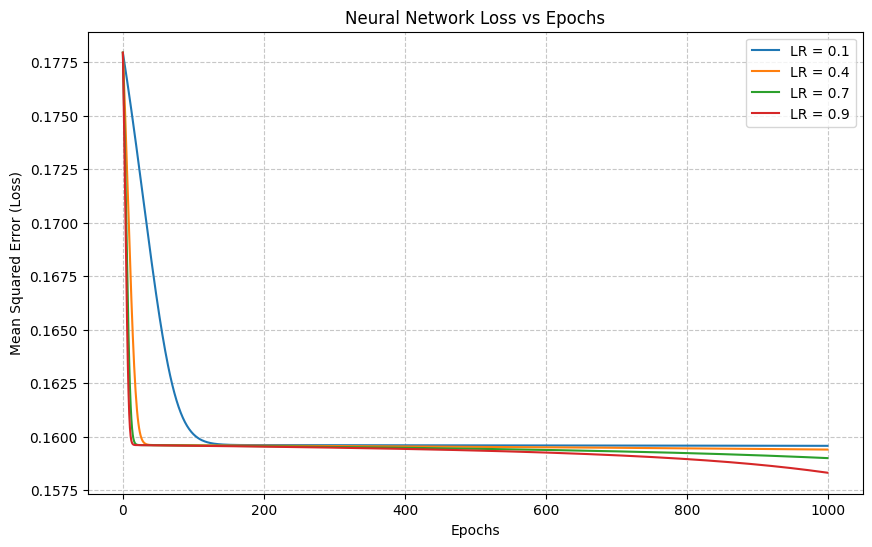

In [11]:
X_task1 = np.array([
[100, 102, 101, 105, 108],
[102, 101, 105, 108, 110],
[101, 105, 108, 110, 112],
[105, 108, 110, 112, 115],
[104, 102, 102, 101, 100],
])
y_task1 = np.array([[1], [1], [1], [1], [0]])
test_data_task1 = np.array([[104, 102, 102, 101, 100]])
lrs = [0.1, 0.4, 0.7, 0.9]
print("Executing Task 1: Original Dataset...")
run_financial_network(X_task1, y_task1, test_data_task1, learning_rates=lrs,
epochs=1000)

Executing Task 2: New Dataset...
--- Learning Rate: 0.1 ---
Prediction Accuracy (Training): 60.00%
Predicted Trend Output for [80 75 70 65 60]: 0.5651
Predicted Class: Increase (1)

--- Learning Rate: 0.4 ---
Prediction Accuracy (Training): 100.00%
Predicted Trend Output for [80 75 70 65 60]: 0.0228
Predicted Class: Decrease (0)

--- Learning Rate: 0.7 ---
Prediction Accuracy (Training): 100.00%
Predicted Trend Output for [80 75 70 65 60]: 0.0061
Predicted Class: Decrease (0)

--- Learning Rate: 0.9 ---
Prediction Accuracy (Training): 100.00%
Predicted Trend Output for [80 75 70 65 60]: 0.0040
Predicted Class: Decrease (0)



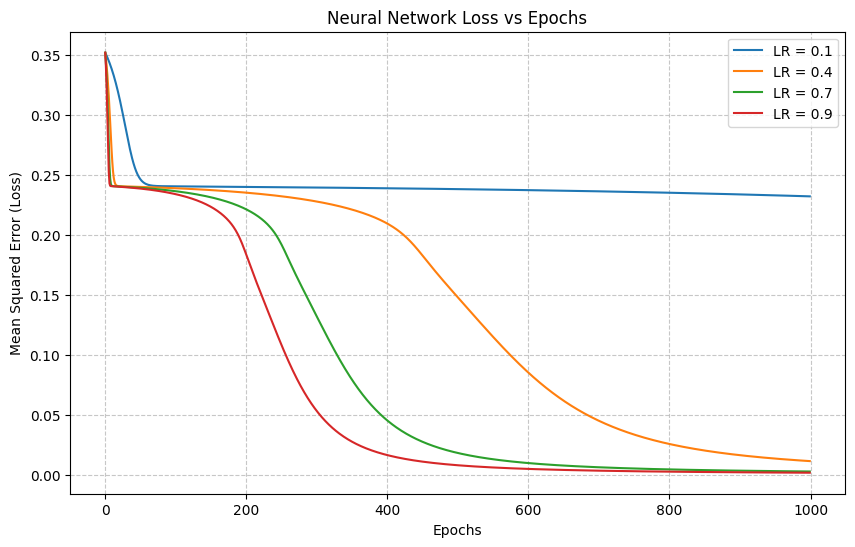

In [12]:
# New Financial Data: Clearer alternating upward/downward 5-day trends
X_task2 = np.array([
[50, 52, 54, 56, 58], [60, 58, 55, 52, 50], [40, 41, 42, 45, 48], [70, 68, 65, 62, 60], [30, 35, 38, 42, 45], # Clear upward trend
# Clear downward trend
# Clear upward trend
# Clear downward trend
# Clear upward trend
])
# Target: 1 for Increase, 0 for Decrease
y_task2 = np.array([[1], [0], [1], [0], [1]])
# New test data representing a severe market drop
test_data_task2 = np.array([[80, 75, 70, 65, 60]])
print("Executing Task 2: New Dataset...")
run_financial_network(X_task2, y_task2, test_data_task2, learning_rates=lrs,
epochs=1000)

In [14]:
# Imports
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
# Helper functions
def sigmoid(x):
  return 1 / (1 + np.exp(-x))
def mean_squared_error(y_pred, y_true_labels, output_size=3):
# One-hot encode true labels
  y_true_one_hot = np.eye(output_size)[y_true_labels]
# Compute MSE
  error = ((y_pred - y_true_one_hot) ** 2).sum() / (2 * y_pred.size)
  return error
def accuracy(y_pred, y_true_one_hot):
  acc = y_pred.argmax(axis=1) == y_true_one_hot.argmax(axis=1)
  return acc.mean()

In [16]:
def train_and_evaluate_nn(test_size, learning_rate, iterations, random_state=4):
  print(f"\n{'-'*60}")
  print(f"RUNNING: test_size={test_size} | lr={learning_rate} |\niterations={iterations}")
  print(f"{'-'*60}")
  # Load dataset
  data = load_iris()
  X = data.data
  y = data.target
  # Split dataset
  X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state
  )
  # Network architecture
  N = y_train.size
  input_size = 4
  hidden_size = 2
  output_size = 3
  # Initialize weights
  np.random.seed(10)
  W1 = np.random.normal(scale=0.5, size=(input_size, hidden_size))
  W2 = np.random.normal(scale=0.5, size=(hidden_size, output_size))
  # One-hot encode training targets for backprop
  y_train_one_hot = np.eye(output_size)[y_train]
  results_list = []
  # Training loop
  for itr in range(iterations):
    # Feedforward propagation
    Z1 = np.dot(X_train, W1)
    A1 = sigmoid(Z1)
    Z2 = np.dot(A1, W2)
    A2 = sigmoid(Z2)
    # Calculate error and accuracy
    mse = mean_squared_error(A2, y_train, output_size)
    acc = accuracy(A2, y_train_one_hot)
    results_list.append({"mse": mse,
                         "accuracy": acc})
    # Backpropagation
    # Output layer error (delta2)
    delta2 = (A2 - y_train_one_hot) * A2 * (1 - A2)
    # Hidden layer error (delta1)
    delta1 = np.dot(delta2, W2.T) * A1 * (1 - A1)
    # Gradients
    dW2 = np.dot(A1.T, delta2) / N
    dW1 = np.dot(X_train.T, delta1) / N
    # Update weights
    W2 = W2 - learning_rate * dW2
    W1 = W1 - learning_rate * dW1
  results = pd.DataFrame(results_list)
  # Visualizing the results (side-by-side to save space)
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
  ax1.plot(results.mse)
  ax1.set_title("Mean Squared Error")
  ax1.set_xlabel("Iterations")
  ax1.set_ylabel("MSE")
  ax2.plot(results.accuracy, color='orange')
  ax2.set_title("Accuracy")
  ax2.set_xlabel("Iterations")
  ax2.set_ylabel("Accuracy")
  plt.tight_layout()
  plt.show()
  # Test the model
  Z1_test = np.dot(X_test, W1)
  A1_test = sigmoid(Z1_test)
  Z2_test = np.dot(A1_test, W2)
  A2_test = sigmoid(Z2_test)
  y_test_one_hot = np.eye(output_size)[y_test]
  test_acc = accuracy(A2_test, y_test_one_hot)
  print(f"--> Test accuracy: {test_acc:.4f}\n")


------------------------------------------------------------
RUNNING: test_size=20 | lr=0.1 |
iterations=5000
------------------------------------------------------------


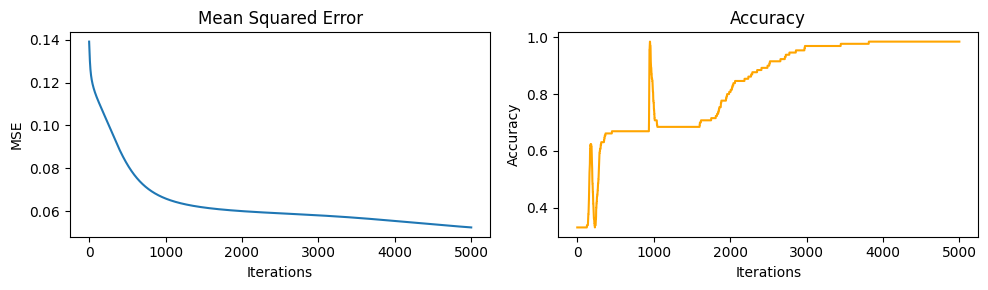

--> Test accuracy: 0.9500



In [17]:
train_and_evaluate_nn(test_size=20, learning_rate=0.1, iterations=5000)


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.1 |
iterations=1000
------------------------------------------------------------


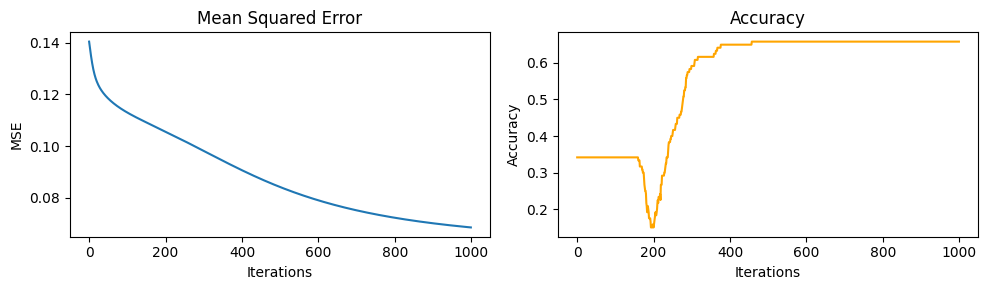

--> Test accuracy: 0.7000


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.1 |
iterations=2000
------------------------------------------------------------


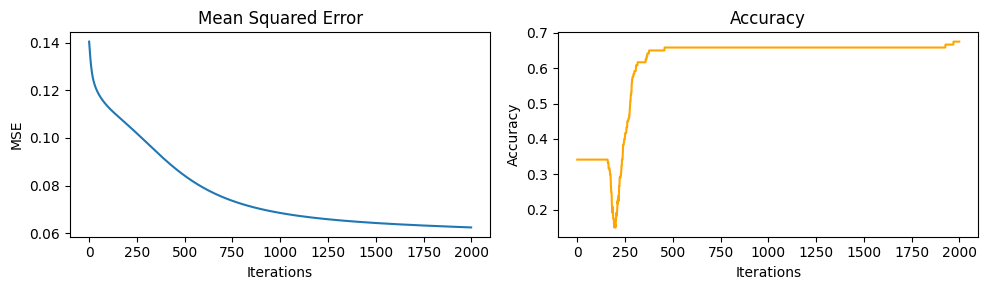

--> Test accuracy: 0.7333


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.1 |
iterations=5000
------------------------------------------------------------


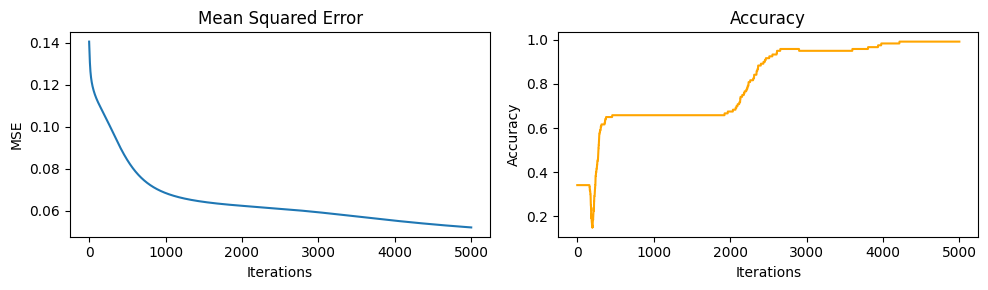

--> Test accuracy: 0.9667


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.4 |
iterations=1000
------------------------------------------------------------


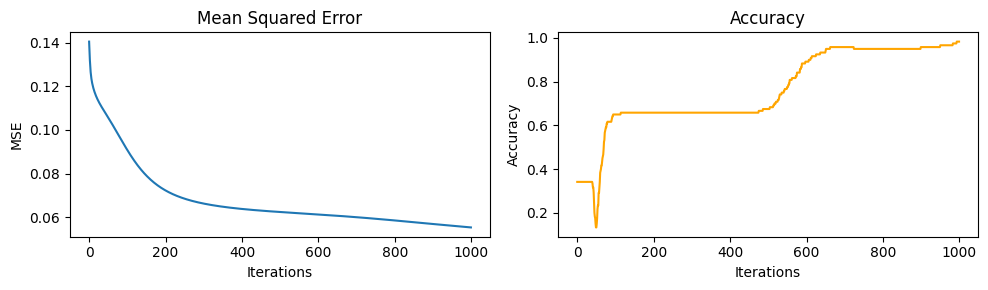

--> Test accuracy: 0.9667


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.4 |
iterations=2000
------------------------------------------------------------


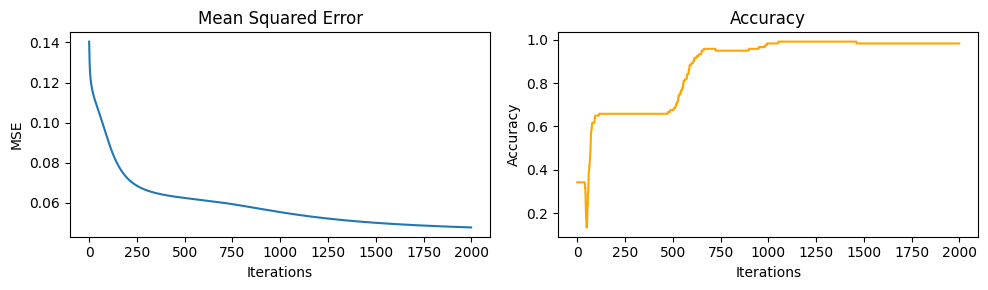

--> Test accuracy: 0.9333


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.4 |
iterations=5000
------------------------------------------------------------


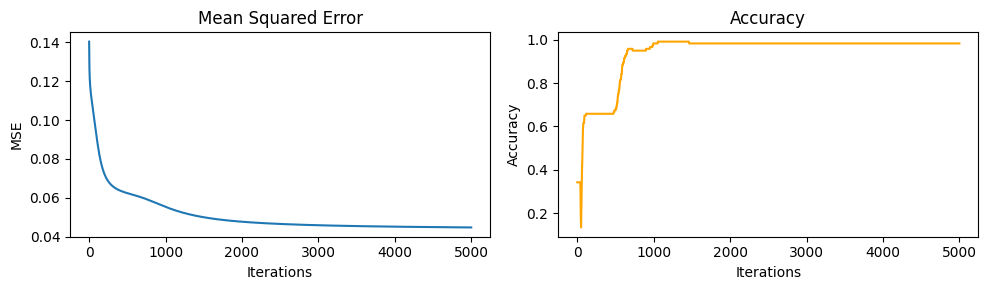

--> Test accuracy: 0.9333


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.8 |
iterations=1000
------------------------------------------------------------


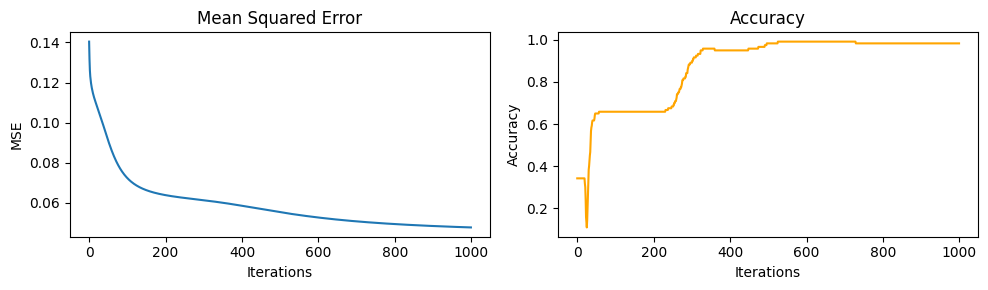

--> Test accuracy: 0.9333


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.8 |
iterations=2000
------------------------------------------------------------


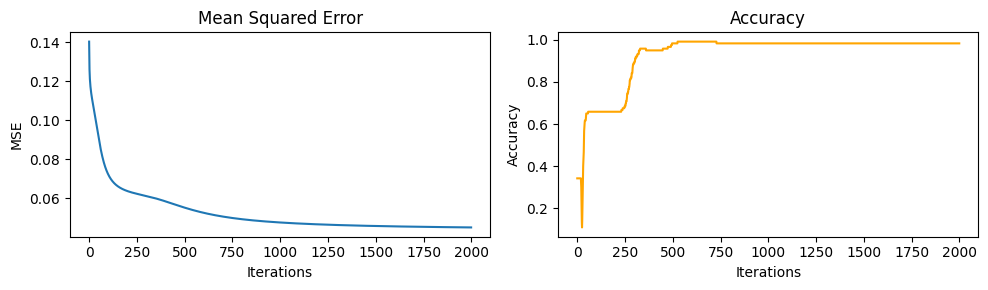

--> Test accuracy: 0.9333


------------------------------------------------------------
RUNNING: test_size=30 | lr=0.8 |
iterations=5000
------------------------------------------------------------


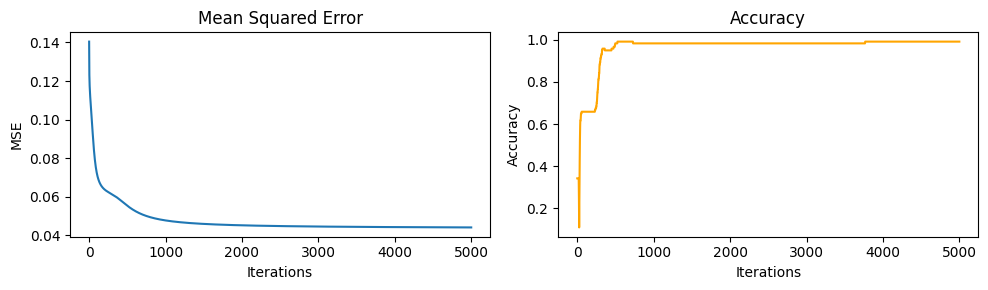

--> Test accuracy: 0.9333


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.1 |
iterations=1000
------------------------------------------------------------


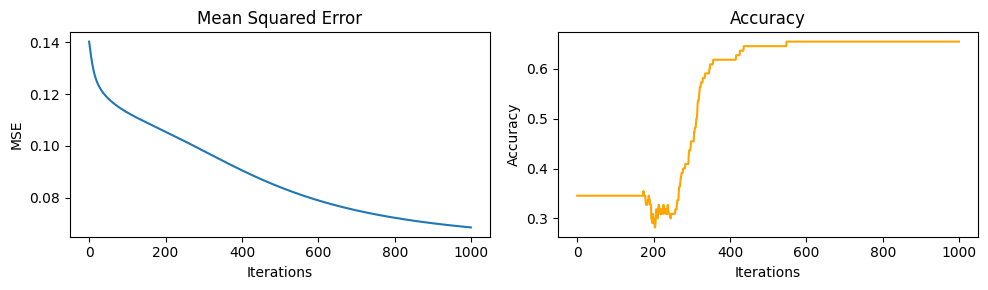

--> Test accuracy: 0.7000


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.1 |
iterations=2000
------------------------------------------------------------


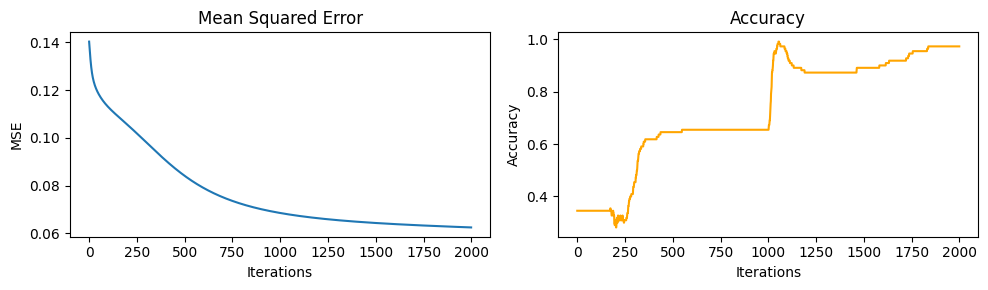

--> Test accuracy: 0.9500


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.1 |
iterations=5000
------------------------------------------------------------


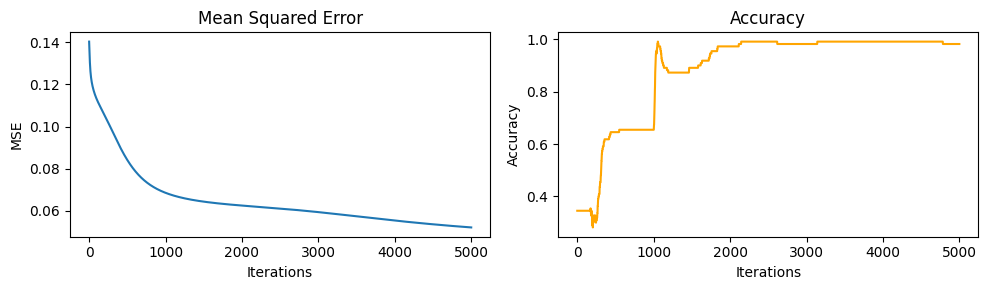

--> Test accuracy: 0.9500


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.4 |
iterations=1000
------------------------------------------------------------


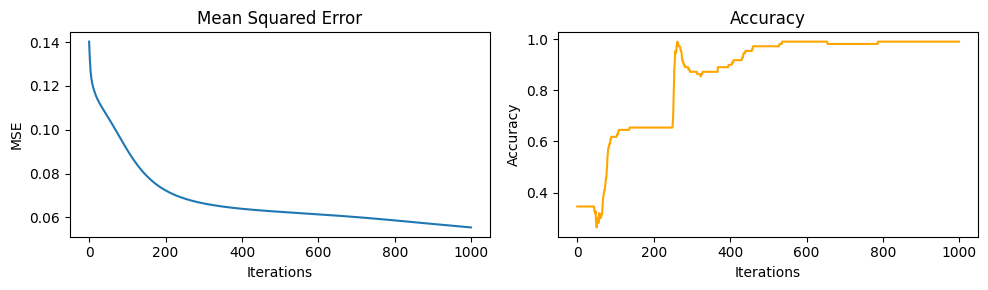

--> Test accuracy: 0.9500


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.4 |
iterations=2000
------------------------------------------------------------


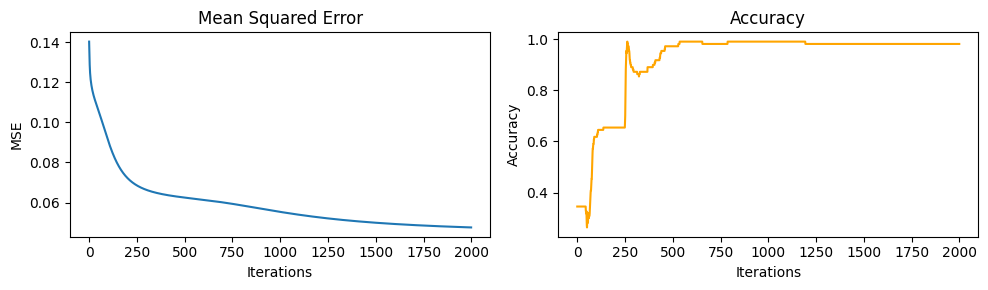

--> Test accuracy: 0.9750


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.4 |
iterations=5000
------------------------------------------------------------


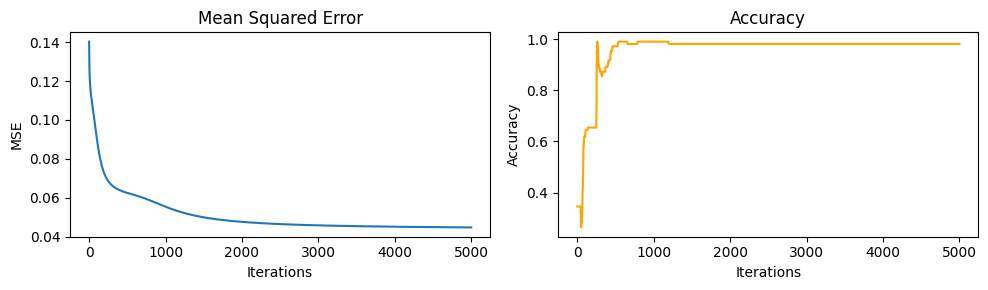

--> Test accuracy: 0.9500


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.8 |
iterations=1000
------------------------------------------------------------


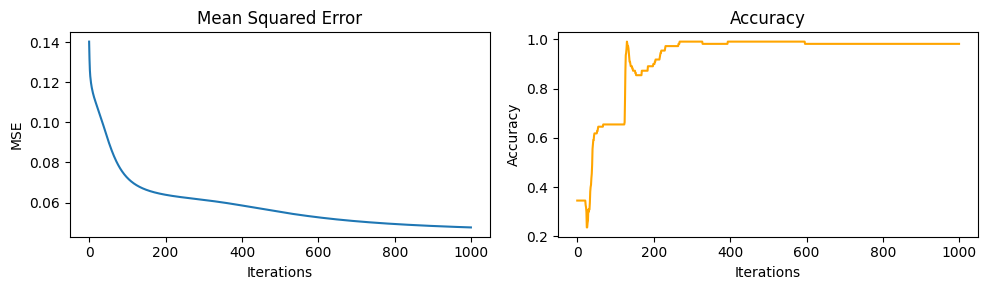

--> Test accuracy: 0.9750


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.8 |
iterations=2000
------------------------------------------------------------


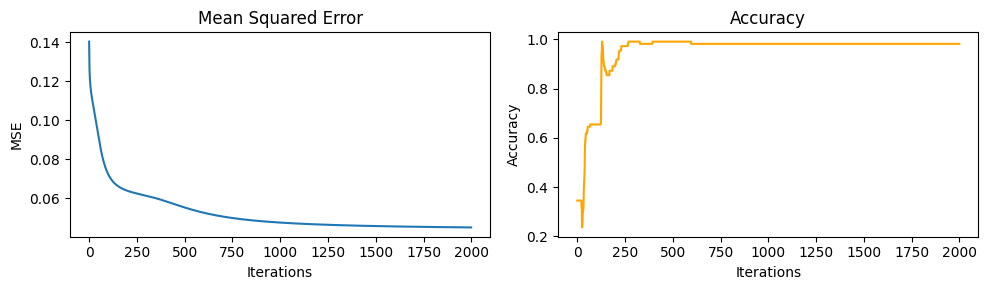

--> Test accuracy: 0.9500


------------------------------------------------------------
RUNNING: test_size=40 | lr=0.8 |
iterations=5000
------------------------------------------------------------


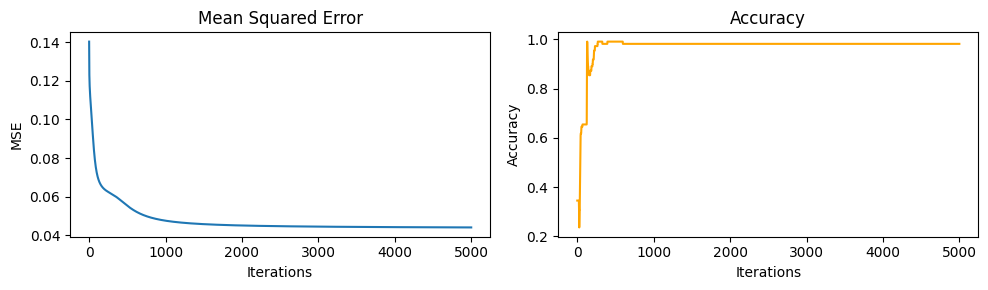

--> Test accuracy: 0.9500



In [18]:
# 2. Execute for multiple test sizes, learning rates, and iterations
test_sizes = [30, 40]
learning_rates = [0.1, 0.4, 0.8]
iterations_list = [1000, 2000, 5000]
for ts in test_sizes:
  for lr in learning_rates:
    for it in iterations_list:
      train_and_evaluate_nn(test_size=ts, learning_rate=lr, iterations=it)